# 04 · Entrenamiento, ajuste y selección de modelos

**Proyecto #2 – Pipeline de Machine Learning · Predict Future Sales (Kaggle)**

Se entrenan y comparan **15 modelos** (5 familias × 3 configuraciones de hiperparámetros) sobre las
variables del pipeline del notebook 03, se elige el ganador por **RMSE de validación** y se arma el
**pipeline completo** (preprocesamiento + modelo ganador) en `models/full_pipeline.pkl`.

| Punto del enunciado | Sección |
|---|---|
| 3.a Al menos 5 modelos distintos | 2 |
| 3.b Al menos 3 configuraciones por modelo (15 en total) | 2, 3 |
| 3.c RMSE como métrica de selección | 1, 3 |
| 3.d Ganador con tienda y producto como variables exógenas / banderas, como paso final del pipeline | 4, 5 |
| 3.e `.pkl` del pipeline completo | 5 |
| Nota: validación secuencial 80/20 (meses 0-26 / 27-33) | 1 |

**Por qué no se usa validación cruzada aleatoria.** En *forecasting* el modelo siempre se usa para
predecir el futuro con información del pasado. Mezclar meses al azar dejaría que el modelo "viera"
meses posteriores a los que valida y daría un RMSE optimista. Por eso la partición es **secuencial**,
como pide el enunciado: entrenar con los meses 0-26 (≈ 80 %) y validar con los meses 27-33 (≈ 20 %).
Es una sola partición fija (equivalente a `GridSearchCV` con `PredefinedSplit`), recorrida
explícitamente para poder medir también el RMSE de entrenamiento y el tiempo de cada modelo.

## 0. Configuración

In [1]:
import os

os.environ["LOGURU_LEVEL"] = "WARNING"

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json
import time

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb

from predict_future_sales.config import MODELS_DIR, PROCESSED_DATA_DIR, RAW_DATA_DIR, REPORTS_DIR
import predict_future_sales.features as pf
from predict_future_sales.plots import COLOR_ACCENT, COLOR_MAIN, COLOR_MUTED, block_label, save_fig, set_style

set_style()
set_config(display="text")
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42
TRAIN_END, VAL_START = 26, 27
N_JOBS = -1

## 1. Datos, partición secuencial y referencias

Se carga el pipeline de preprocesamiento **ya ajustado** con los meses 0-26 (notebook 03) y se
transforman entrenamiento y validación. La métrica es el **RMSE** sobre `item_cnt_month` en [0, 20];
las predicciones también se recortan a [0, 20] antes de evaluar (igual que en Kaggle).

In [2]:
preprocessing_pipeline = joblib.load(MODELS_DIR / "preprocessing_pipeline.pkl")
monthly = pd.read_csv(PROCESSED_DATA_DIR / "monthly_shop_item.csv")
grid = pf.build_monthly_grid(monthly)

train = grid[grid.date_block_num <= TRAIN_END]
val = grid[grid.date_block_num >= VAL_START]
y_train, y_val = train[pf.TARGET].to_numpy(), val[pf.TARGET].to_numpy()

t0 = time.perf_counter()
X_train = preprocessing_pipeline.transform(train[pf.KEYS])
X_val = preprocessing_pipeline.transform(val[pf.KEYS])
print(f"Preprocesamiento: {time.perf_counter() - t0:.0f} s")
print(f"Entrenamiento: meses 0-{TRAIN_END} · {X_train.shape[0]:,} filas ({X_train.shape[0] / len(grid):.1%})")
print(f"Validación:    meses {VAL_START}-33 · {X_val.shape[0]:,} filas ({X_val.shape[0] / len(grid):.1%})")
print(f"Variables: {X_train.shape[1]}")

# Muestra fija de entrenamiento para medir el RMSE de entrenamiento (diagnóstico de sobreajuste)
rng = np.random.default_rng(RANDOM_STATE)
train_idx = rng.choice(len(X_train), size=1_000_000, replace=False)


def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, np.clip(y_pred, *pf.TARGET_CLIP))

Preprocesamiento: 30 s
Entrenamiento: meses 0-26 · 9,299,440 filas (85.2%)
Validación:    meses 27-33 · 1,614,364 filas (14.8%)
Variables: 40


In [3]:
# Referencias ingenuas: cualquier modelo debe superarlas
history = preprocessing_pipeline.named_steps["history"]
raw_val = history.transform(val[pf.KEYS])  # variables sin escalar (lags en unidades)
baselines = pd.Series({
    "predecir 0": rmse(y_val, np.zeros_like(y_val)),
    "predecir la media de entrenamiento": rmse(y_val, np.full_like(y_val, y_train.mean())),
    "repetir el mes anterior (lag 1)": rmse(y_val, raw_val["cnt_lag_1"].fillna(0).to_numpy()),
    "promedio de los últimos 3 meses": rmse(y_val, raw_val[["cnt_lag_1", "cnt_lag_2", "cnt_lag_3"]].fillna(0).mean(axis=1).to_numpy()),
}, name="RMSE validación")
baselines.to_frame()

,RMSE validación
predecir 0,1.1159
predecir la media de entrenamiento,1.0856
repetir el mes anterior (lag 1),1.0373
promedio de los últimos 3 meses,0.9632


## 2. Modelos y configuraciones (5 × 3 = 15)

| Familia | Por qué se incluye | Hiperparámetros que se varían |
|---|---|---|
| **Ridge** (lineal regularizado) | referencia lineal; necesita el escalado del pipeline | `alpha` (fuerza de la regularización L2) |
| **Árbol de decisión** | no lineal e interpretable; base de los ensambles | `max_depth`, `min_samples_leaf` |
| **Random Forest** (bagging) | promedia árboles profundos: menos varianza que un árbol | `n_estimators`, `max_depth`, `min_samples_leaf` |
| **XGBoost** (boosting) | árboles secuenciales que corrigen el error anterior | `max_depth`, `learning_rate`, `n_estimators` |
| **LightGBM** (boosting por hojas) | boosting muy eficiente para millones de filas | `num_leaves`, `learning_rate`, `n_estimators` |

Para que el torneo sea viable con 9.3 millones de filas, Random Forest usa `max_samples=0.1` (cada
árbol ve un 10 % distinto de las filas: sigue siendo *bagging*) y los boosting usan submuestreo de
filas y columnas. Las configuraciones van de más simple / más regularizada a más compleja, para ver
dónde empieza el sobreajuste.

In [4]:
rf_common = dict(max_samples=0.1, max_features=0.5, n_jobs=N_JOBS, random_state=RANDOM_STATE)
xgb_common = dict(subsample=0.5, colsample_bytree=0.8, tree_method="hist", n_jobs=N_JOBS, random_state=RANDOM_STATE)
lgb_common = dict(subsample=0.5, subsample_freq=1, colsample_bytree=0.8, n_jobs=N_JOBS, random_state=RANDOM_STATE, verbose=-1)

candidates = {
    "Ridge": [
        Ridge(alpha=0.1),
        Ridge(alpha=10.0),
        Ridge(alpha=1000.0),
    ],
    "Árbol de decisión": [
        DecisionTreeRegressor(max_depth=8, min_samples_leaf=100, random_state=RANDOM_STATE),
        DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=RANDOM_STATE),
        DecisionTreeRegressor(max_depth=16, min_samples_leaf=200, random_state=RANDOM_STATE),
    ],
    "Random Forest": [
        RandomForestRegressor(n_estimators=50, max_depth=10, min_samples_leaf=20, **rf_common),
        RandomForestRegressor(n_estimators=50, max_depth=14, min_samples_leaf=20, **rf_common),
        RandomForestRegressor(n_estimators=80, max_depth=16, min_samples_leaf=50, **rf_common),
    ],
    "XGBoost": [
        xgb.XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, **xgb_common),
        xgb.XGBRegressor(n_estimators=300, max_depth=8, learning_rate=0.1, **xgb_common),
        xgb.XGBRegressor(n_estimators=500, max_depth=10, learning_rate=0.05, **xgb_common),
    ],
    "LightGBM": [
        lgb.LGBMRegressor(n_estimators=300, num_leaves=31, learning_rate=0.1, **lgb_common),
        lgb.LGBMRegressor(n_estimators=300, num_leaves=127, learning_rate=0.1, **lgb_common),
        lgb.LGBMRegressor(n_estimators=600, num_leaves=255, learning_rate=0.05, **lgb_common),
    ],
}
TUNED = {
    "Ridge": ["alpha"],
    "Árbol de decisión": ["max_depth", "min_samples_leaf"],
    "Random Forest": ["n_estimators", "max_depth", "min_samples_leaf"],
    "XGBoost": ["n_estimators", "max_depth", "learning_rate"],
    "LightGBM": ["n_estimators", "num_leaves", "learning_rate"],
}
print(f"{len(candidates)} familias · {sum(len(v) for v in candidates.values())} modelos")

5 familias · 15 modelos


## 3. Torneo: entrenamiento y evaluación de los 15 modelos

Cada modelo se entrena con los meses 0-26 y se evalúa con:

- **RMSE de validación** (meses 27-33): métrica de selección;
- **RMSE de entrenamiento** (muestra fija de 1 millón de filas de 0-26): si es mucho menor que el de
  validación, el modelo memoriza en lugar de generalizar (sobreajuste);
- tiempo de entrenamiento.

In [5]:
results, fitted = [], {}
for family, models in candidates.items():
    for i, model in enumerate(models, start=1):
        name = f"{family} #{i}"
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        fit_s = time.perf_counter() - t0
        rmse_val = rmse(y_val, model.predict(X_val))
        rmse_tr = rmse(y_train[train_idx], model.predict(X_train.iloc[train_idx]))
        params = {p: model.get_params()[p] for p in TUNED[family]}
        results.append({"modelo": name, "familia": family, "configuración": params,
                        "RMSE entrenamiento": rmse_tr, "RMSE validación": rmse_val,
                        "brecha (val - train)": rmse_val - rmse_tr, "tiempo (s)": fit_s})
        fitted[name] = model
        print(f"{name:22s} val={rmse_val:.4f} train={rmse_tr:.4f} {fit_s:6.0f} s  {params}", flush=True)

results = pd.DataFrame(results).set_index("modelo")
print(f"\nModelos entrenados: {len(results)}")

Ridge #1               val=0.9092 train=1.0217      1 s  {'alpha': 0.1}


Ridge #2               val=0.9092 train=1.0217      1 s  {'alpha': 10.0}


Ridge #3               val=0.9091 train=1.0217      1 s  {'alpha': 1000.0}


Árbol de decisión #1   val=0.8493 train=0.9400     60 s  {'max_depth': 8, 'min_samples_leaf': 100}


Árbol de decisión #2   val=0.8558 train=0.8961     86 s  {'max_depth': 12, 'min_samples_leaf': 50}


Árbol de decisión #3   val=0.8453 train=0.8987    108 s  {'max_depth': 16, 'min_samples_leaf': 200}


... (6 outputs left out)

LightGBM #1            val=0.8130 train=0.8537     48 s  {'n_estimators': 300, 'num_leaves': 31, 'learning_rate': 0.1}


LightGBM #2            val=0.8165 train=0.8086     52 s  {'n_estimators': 300, 'num_leaves': 127, 'learning_rate': 0.1}


LightGBM #3            val=0.8155 train=0.7815    109 s  {'n_estimators': 600, 'num_leaves': 255, 'learning_rate': 0.05}



Modelos entrenados: 15


In [6]:
tabla = results.sort_values("RMSE validación").copy()
tabla["configuración"] = tabla["configuración"].map(lambda d: ", ".join(f"{k}={v}" for k, v in d.items()))
tabla.insert(0, "posición", range(1, len(tabla) + 1))
REPORTS_DIR.mkdir(exist_ok=True)
tabla.to_csv(REPORTS_DIR / "model_tournament_results.csv")
tabla

,posición,familia,configuración,RMSE entrenamiento,RMSE validación,brecha (val - train),tiempo (s)
modelo,,,,,,,
Random Forest #2,1,Random Forest,"n_estimators=50, max_depth=14, min_samples_leaf=20",0.8889,0.8096,-0.0793,95.3710
Random Forest #3,2,Random Forest,"n_estimators=80, max_depth=16, min_samples_leaf=50",0.9006,0.8128,-0.0878,160.3058
LightGBM #1,3,LightGBM,"n_estimators=300, num_leaves=31, learning_rate=0.1",0.8537,0.8130,-0.0407,47.6875
LightGBM #3,4,LightGBM,"n_estimators=600, num_leaves=255, learning_rate=0.05",0.7815,0.8155,0.0340,109.0216
Random Forest #1,5,Random Forest,"n_estimators=50, max_depth=10, min_samples_leaf=20",0.9075,0.8163,-0.0911,77.8687
LightGBM #2,6,LightGBM,"n_estimators=300, num_leaves=127, learning_rate=0.1",0.8086,0.8165,0.0079,51.5667
XGBoost #1,7,XGBoost,"n_estimators=300, max_depth=6, learning_rate=0.1",0.8572,0.8184,-0.0388,73.5689
XGBoost #3,8,XGBoost,"n_estimators=500, max_depth=10, learning_rate=0.05",0.7737,0.8199,0.0463,170.9912
XGBoost #2,9,XGBoost,"n_estimators=300, max_depth=8, learning_rate=0.1",0.8149,0.8237,0.0089,86.0856


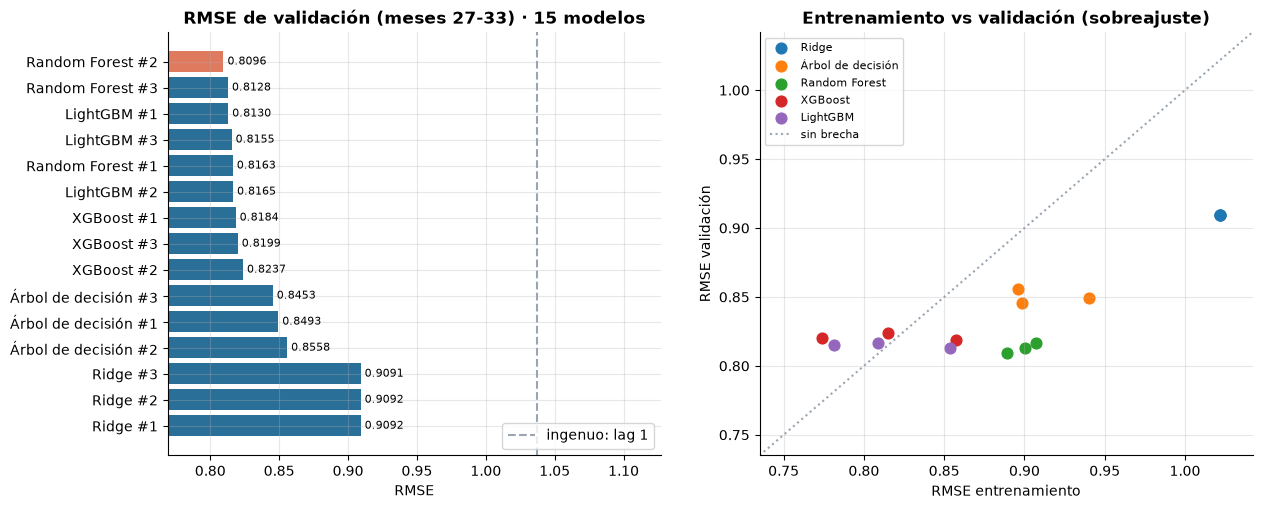

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
order = results.sort_values("RMSE validación")
best_name = order.index[0]
colors = [COLOR_ACCENT if n == best_name else COLOR_MAIN for n in order.index]
axes[0].barh(order.index[::-1], order["RMSE validación"][::-1], color=colors[::-1])
axes[0].axvline(baselines["repetir el mes anterior (lag 1)"], color=COLOR_MUTED, ls="--", label="ingenuo: lag 1")
axes[0].set_xlim(order["RMSE validación"].min() * 0.95, max(order["RMSE validación"].max(), baselines.max()) * 1.01)
for y, v in enumerate(order["RMSE validación"][::-1]):
    axes[0].text(v, y, f" {v:.4f}", va="center", fontsize=8)
axes[0].set(title="RMSE de validación (meses 27-33) · 15 modelos", xlabel="RMSE")
axes[0].legend(loc="lower right")

for family, grp in results.groupby("familia", sort=False):
    axes[1].scatter(grp["RMSE entrenamiento"], grp["RMSE validación"], s=60, label=family)
lims = [results[["RMSE entrenamiento", "RMSE validación"]].min().min() * 0.95,
        results[["RMSE entrenamiento", "RMSE validación"]].max().max() * 1.02]
axes[1].plot(lims, lims, color=COLOR_MUTED, ls=":", label="sin brecha")
axes[1].set(title="Entrenamiento vs validación (sobreajuste)", xlabel="RMSE entrenamiento", ylabel="RMSE validación",
            xlim=lims, ylim=lims)
axes[1].legend(fontsize=8)
save_fig(fig, "p2_04a_torneo_modelos")
plt.show()

In [8]:
# Mejor configuración de cada familia
best_by_family = results.loc[results.groupby("familia")["RMSE validación"].idxmin()].sort_values("RMSE validación")
best_by_family[["configuración", "RMSE entrenamiento", "RMSE validación", "tiempo (s)"]]

,configuración,RMSE entrenamiento,RMSE validación,tiempo (s)
modelo,,,,
Random Forest #2,"{'n_estimators': 50, 'max_depth': 14, 'min_samples_leaf': 20}",0.8889,0.8096,95.3710
LightGBM #1,"{'n_estimators': 300, 'num_leaves': 31, 'learning_rate': 0.1}",0.8537,0.8130,47.6875
XGBoost #1,"{'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.1}",0.8572,0.8184,73.5689
Árbol de decisión #3,"{'max_depth': 16, 'min_samples_leaf': 200}",0.8987,0.8453,108.3020
Ridge #3,{'alpha': 1000.0},1.0217,0.9091,1.1164


**Interpretación del torneo.** **Los 15 modelos superan a todas las referencias ingenuas** (la mejor, el promedio de los últimos 3 meses, tiene RMSE 0.9632). Resultados por familia:

- **Ridge (0.909)** es el más débil y prácticamente no cambia con `alpha` (0.1, 10 o 1000): con 9.3 millones de filas la penalización es insignificante frente a los datos, y un modelo lineal no puede representar interacciones como "producto nuevo *y* categoría de juegos".
- **Árbol de decisión (0.845-0.856)** mejora mucho a Ridge, pero un solo árbol es inestable: el de profundidad 12 sale peor que los de profundidad 8 y 16.
- **Ensambles (0.810-0.824)**: los tres ocupan las primeras 9 posiciones. Las diferencias entre los mejores son pequeñas (Random Forest #2 0.8096, Random Forest #3 0.8128, LightGBM #1 0.8130).

**Sobreajuste.** En casi todos los modelos el RMSE de entrenamiento es *mayor* que el de validación. No indica falta de ajuste: los meses de entrenamiento incluyen 2013, con más volumen, los picos de diciembre de 2013 y 2014 y los primeros meses sin lags, mientras que la validación (abril-octubre 2015) no tiene ningún diciembre y es un periodo más tranquilo. Por eso la señal útil es **comparar configuraciones dentro de cada familia**. En los boosting, las configuraciones más complejas bajan mucho el error de entrenamiento (LightGBM #3: 0.78; XGBoost #3: 0.77) sin mejorar validación (0.8155 y 0.8199 frente a 0.8130 y 0.8184 de las más simples): memorizan. En las tres familias de árboles gana una configuración intermedia o regularizada (LightGBM con 31 hojas, XGBoost con profundidad 6, Random Forest con profundidad 14). Random Forest es el más robusto porque promedia 50 árboles entrenados cada uno con un 10 % distinto de las filas, lo que reduce la varianza sin necesitar una tasa de aprendizaje.

## 4. Análisis del modelo ganador

### 4.1 ¿Tienda y producto como variables exógenas?

El enunciado pide que el ganador prediga considerando **tienda y producto como variables exógenas o
banderas**. En este modelo global entran así:

- **Tienda**: `shop_id` (código), `city` (mean encoding), `shop_type_*` (one-hot) y la historia de
  la tienda (`shop_cnt_lag_*`, `shop_cat_cnt_lag_*`).
- **Producto**: `item_category_id`, `category_group`, `item_price_last`, su historia en todas las
  tiendas (`item_cnt_lag_*`) y las **banderas** `item_is_new`, `pair_is_new` con su antigüedad.

La importancia de variables del ganador muestra cuánto pesa cada grupo.

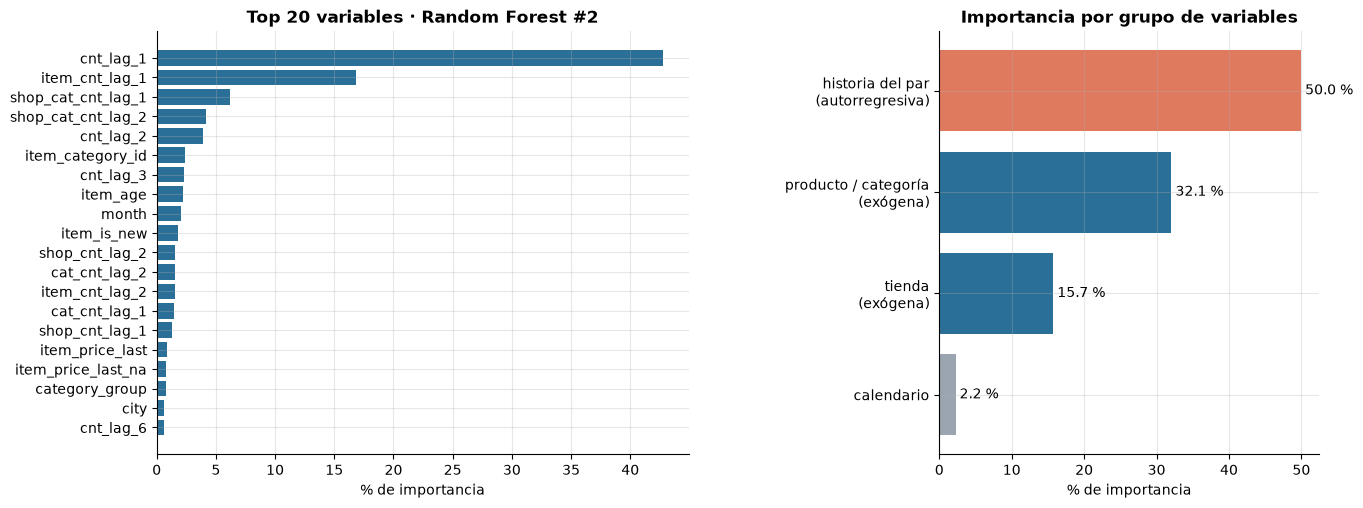

,% importancia
historia del par (autorregresiva),49.9650
producto / categoría (exógena),32.0539
tienda (exógena),15.7389
calendario,2.2422


In [9]:
best_model = fitted[best_name]
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns, dtype=float)
else:  # modelo lineal: magnitud del coeficiente (variables escaladas)
    importance = pd.Series(np.abs(best_model.coef_), index=X_train.columns)
importance = importance / importance.sum() * 100


def group_of(col):
    if col.startswith("cnt_lag"):
        return "historia del par\n(autorregresiva)"
    if col.startswith(("shop_", "city")) or col == "shop_id":
        return "tienda\n(exógena)"
    if col.startswith(("item_", "cat_", "category", "pair_")):
        return "producto / categoría\n(exógena)"
    return "calendario"


fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.4, 1], "wspace": 0.55})
top = importance.sort_values().tail(20)
axes[0].barh(top.index, top.values, color=COLOR_MAIN)
axes[0].set(title=f"Top 20 variables · {best_name}", xlabel="% de importancia")
by_group = importance.groupby(importance.index.map(group_of)).sum().sort_values()
axes[1].barh(by_group.index, by_group.values, color=[COLOR_MUTED, COLOR_MAIN, COLOR_MAIN, COLOR_ACCENT][-len(by_group):])
for y, v in enumerate(by_group.values):
    axes[1].text(v, y, f" {v:.1f} %", va="center")
axes[1].set(title="Importancia por grupo de variables", xlabel="% de importancia")
save_fig(fig, "p2_04b_importancia_variables")
plt.show()
by_group.rename(index=lambda s: s.replace("\n", " ")).sort_values(ascending=False).to_frame("% importancia")

### 4.2 Error por segmento y por mes

El 48 % de los pares del test no tiene historia propia (`pair_is_new`) y el 7 % son productos nuevos
(`item_is_new`). Se mide el error del ganador en cada segmento de validación y se compara con el
pronóstico ingenuo (lag 1), que no sabe nada de tienda ni producto.

In [10]:
pred_val = np.clip(best_model.predict(X_val), *pf.TARGET_CLIP)
seg = pd.DataFrame({
    "segmento": np.select([raw_val.item_is_new.to_numpy() == 1, raw_val.pair_is_new.to_numpy() == 1],
                          ["producto nuevo", "producto conocido, par nuevo"], "par con historia"),
    "y": y_val, "pred": pred_val, "lag1": raw_val["cnt_lag_1"].fillna(0).to_numpy(),
    "mes": val.date_block_num.to_numpy(),
})
by_seg = seg.groupby("segmento").apply(lambda d: pd.Series({
    "% de filas": len(d) / len(seg) * 100, "venta media real": d.y.mean(), "venta media predicha": d.pred.mean(),
    f"RMSE {best_name}": rmse(d.y, d.pred), "RMSE ingenuo (lag 1)": rmse(d.y, d.lag1)}), include_groups=False)
by_seg

,% de filas,venta media real,venta media predicha,RMSE Random Forest #2,RMSE ingenuo (lag 1)
segmento,,,,,
par con historia,56.1697,0.3755,0.3812,0.8428,1.1408
"producto conocido, par nuevo",38.4070,0.0537,0.0633,0.3765,0.4009
producto nuevo,5.4233,0.5563,0.5867,1.9297,2.2854


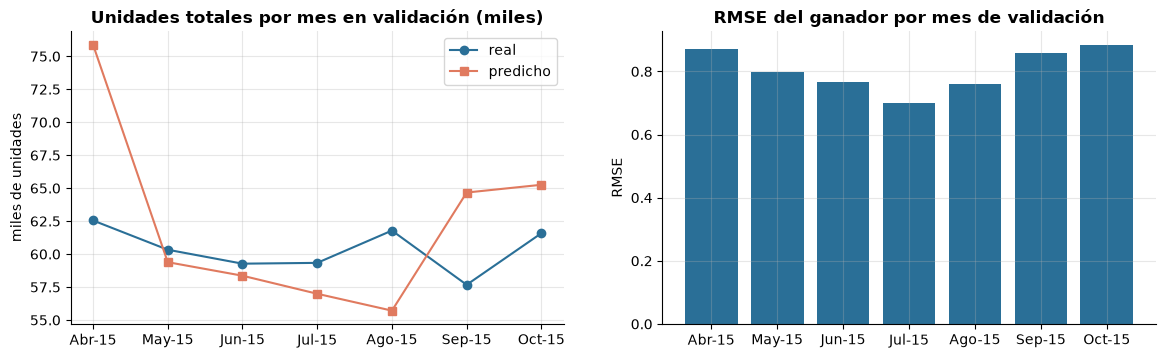

,real,predicho,RMSE
mes,,,
27,"62,550.0000","75,882.7558",0.8698
28,"60,331.0000","59,387.1490",0.7996
29,"59,274.0000","58,360.6575",0.7651
30,"59,335.0000","56,992.3588",0.7002
31,"61,784.0000","55,712.4034",0.7616
32,"57,672.0000","64,667.2561",0.8584
33,"61,583.0000","65,255.9753",0.8829


In [11]:
by_month = seg.groupby("mes").agg(real=("y", "sum"), predicho=("pred", "sum"))
by_month["RMSE"] = seg.groupby("mes").apply(lambda d: rmse(d.y, d.pred), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
x = [block_label(m) for m in by_month.index]
axes[0].plot(x, by_month.real / 1e3, marker="o", color=COLOR_MAIN, label="real")
axes[0].plot(x, by_month.predicho / 1e3, marker="s", color=COLOR_ACCENT, label="predicho")
axes[0].set(title="Unidades totales por mes en validación (miles)", ylabel="miles de unidades")
axes[0].legend()
axes[1].bar(x, by_month.RMSE, color=COLOR_MAIN)
axes[1].set(title="RMSE del ganador por mes de validación", ylabel="RMSE")
save_fig(fig, "p2_04c_validacion_por_mes")
plt.show()
by_month

**Interpretación.** **Ganador: Random Forest #2** (50 árboles, profundidad máxima 14, mínimo 20 filas por hoja, 50 % de variables por división). Su RMSE de validación de **0.8096** es un 22 % mejor que repetir el mes anterior (1.0373) y un 16 % mejor que el promedio de 3 meses (0.9632).

**Tienda y producto como exógenas.** La historia propia del par explica el 50 % de la importancia, pero las variables **exógenas de producto y categoría suman 32 %** y las **de tienda 16 %**. Casi la mitad de lo que usa el modelo viene de tienda y producto, no de la serie misma; el calendario aporta 2 %.

**Por segmento.** El modelo mejora al pronóstico ingenuo en los tres grupos:
- **Pares con historia** (56 % de las filas): RMSE 0.843 frente a 1.141.
- **Pares nuevos de productos conocidos** (38 %): 0.377 frente a 0.401. Venden muy poco (0.054 unidades de media) y el modelo lo reproduce (predice 0.063).
- **Productos nuevos** (5.4 %): el segmento más difícil, RMSE 1.93 frente a 2.29. Venden en promedio 0.56 unidades, más que los pares nuevos de productos conocidos, por el efecto lanzamiento que mostró el EDA. Gracias a la bandera `item_is_new` y a la categoría, el modelo predice un nivel similar (0.59), aunque no tiene historia propia.

**Por mes.** El RMSE de validación va de 0.70 (julio 2015) a 0.88 (abril y octubre 2015). En el total de unidades, el modelo sobreestima abril 2015 en 21 % (75.9 mil frente a 62.6 mil), subestima agosto en 10 % y sobreestima septiembre y octubre en 12 % y 6 %. El error mensual agregado oscila alrededor del valor real, sin un sesgo sistemático en una sola dirección.

## 5. Pipeline completo: preprocesamiento + modelo ganador

El modelo ganador se agrega como **paso final** del pipeline de preprocesamiento. Para pronosticar
noviembre 2015 se **re-entrena con los 34 meses (0-33)** usando los mismos hiperparámetros: la
validación ya cumplió su función (elegir modelo y configuración) y los meses 27-33 son justamente los
más recientes, los más informativos para el mes 34. Todos los parámetros del preprocesamiento
(medianas, encoders, percentil, escalado) se vuelven a aprender con esos meses al ajustar el pipeline.

In [12]:
best_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in best_model.get_params().items()
               if isinstance(v, (int, float, str, bool, type(None))) or hasattr(v, "item")}
full_pipeline = Pipeline(steps=clone(preprocessing_pipeline).steps + [("model", clone(best_model))])

del X_train, X_val, fitted  # libera memoria antes de re-entrenar con 10.9 millones de filas
t0 = time.perf_counter()
full_pipeline.fit(grid[pf.KEYS], grid[pf.TARGET])
print(f"Pipeline completo re-entrenado con meses 0-33 ({len(grid):,} filas) en {time.perf_counter() - t0:.0f} s")
pd.DataFrame(
    [{"paso": name, "operador": type(step).__name__} for name, step in full_pipeline.steps],
    index=pd.RangeIndex(1, len(full_pipeline.steps) + 1, name="#"),
).assign(rol=lambda d: np.where(d.paso == "model", "modelo ganador (paso final)", "preprocesamiento"))

Pipeline completo re-entrenado con meses 0-33 (10,913,804 filas) en 165 s


,paso,operador,rol
#,,,
1,history,SalesHistoryFeatures,preprocesamiento
2,map_city,Mapper,preprocesamiento
3,map_shop_type,Mapper,preprocesamiento
4,map_category_group,Mapper,preprocesamiento
5,drop_keys,DropFeatures,preprocesamiento
6,missing_indicator,AddMissingIndicator,preprocesamiento
7,num_imputer,MeanMedianImputer,preprocesamiento
8,cat_imputer,CategoricalImputer,preprocesamiento
9,onehot,OneHotEncoder,preprocesamiento


In [13]:
FULL_PATH = MODELS_DIR / "full_pipeline.pkl"
joblib.dump(full_pipeline, FULL_PATH, compress=3)
size_mb = FULL_PATH.stat().st_size / 1e6
print(f"Guardado: models/{FULL_PATH.name} ({size_mb:.1f} MB)")
assert size_mb < 100, "GitHub rechaza archivos de más de 100 MB"

# Resumen del ganador (lo usa el script predict_future_sales/modeling/train.py)
summary = {
    "modelo": best_name,
    "familia": results.loc[best_name, "familia"],
    "clase": type(best_model).__name__,
    "hiperparametros": best_params,
    "rmse_validacion": round(float(results.loc[best_name, "RMSE validación"]), 4),
    "rmse_entrenamiento": round(float(results.loc[best_name, "RMSE entrenamiento"]), 4),
    "rmse_ingenuo_lag1": round(float(baselines["repetir el mes anterior (lag 1)"]), 4),
    "entrenamiento_final": "meses 0-33",
}
(REPORTS_DIR / "best_model.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
pd.Series({k: v for k, v in summary.items() if k != "hiperparametros"}).to_frame("valor")

Guardado: models/full_pipeline.pkl (24.6 MB)


,valor
modelo,Random Forest #2
familia,Random Forest
clase,RandomForestRegressor
rmse_validacion,0.8096
rmse_entrenamiento,0.8889
rmse_ingenuo_lag1,1.0373
entrenamiento_final,meses 0-33


In [14]:
# Comprobación: el .pkl se carga y predice directo sobre test.csv crudo (más el mes 34)
reloaded = joblib.load(FULL_PATH)
test = pd.read_csv(RAW_DATA_DIR / "test.csv")
check = np.clip(reloaded.predict(test.assign(date_block_num=pf.TEST_BLOCK)[pf.KEYS].head(1000)), *pf.TARGET_CLIP)
print("Pasos del pipeline completo:", [n for n, _ in reloaded.steps])
print(f"Predicción de prueba (1,000 filas de test.csv): media {check.mean():.3f}, rango [{check.min():.2f}, {check.max():.2f}]")

Pasos del pipeline completo: ['history', 'map_city', 'map_shop_type', 'map_category_group', 'drop_keys', 'missing_indicator', 'num_imputer', 'cat_imputer', 'onehot', 'mean_encoder', 'outliers', 'log', 'scaler', 'float32', 'model']
Predicción de prueba (1,000 filas de test.csv): media 0.636, rango [0.00, 19.20]


## 6. Conclusiones

1. Se entrenaron y compararon **15 modelos** de 5 familias distintas (Ridge, árbol de decisión, Random Forest, XGBoost y LightGBM), 3 configuraciones cada uno, con **validación secuencial** (entrenamiento meses 0-26, validación 27-33) y **RMSE** como métrica de selección. La tabla completa quedó en `reports/model_tournament_results.csv`.
2. El ganador es **Random Forest** (`n_estimators=50`, `max_depth=14`, `min_samples_leaf=20`) con **RMSE de validación 0.8096**, 22 % mejor que el pronóstico ingenuo. Los ensambles de árboles dominan, y en el boosting más complejidad significó sobreajuste.
3. El modelo usa **tienda y producto como variables exógenas** (48 % de la importancia) y banderas de novedad, con las que pronostica también los pares y productos sin historia.
4. El ganador se agregó como **paso final** del pipeline de preprocesamiento, se re-entrenó con los meses 0-33 (10.9 millones de filas) y se guardó en **`models/full_pipeline.pkl` (24.6 MB, 15 pasos)**, verificado al cargarlo y predecir directo sobre `test.csv` crudo. El resumen del ganador quedó en `reports/best_model.json`.

**Siguiente paso:** `05_inference_calculation.ipynb` usa `models/full_pipeline.pkl` para predecir
todo `test.csv` y genera el archivo de envío.